# ZADANIE 1

a) Wykonaj poniższy skrypt i przeanalizuj go:

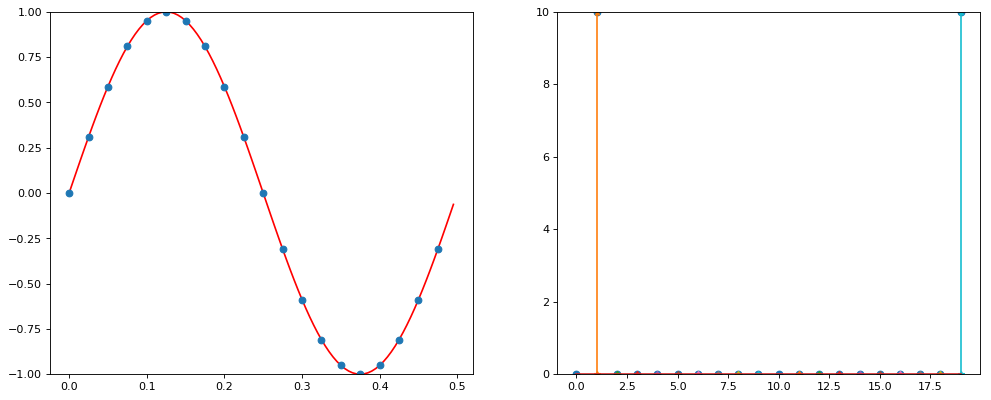

In [ ]:
from __future__ import division
from pylab import *
from numpy import *
from scipy import *
from ipywidgets import *
import math as mt

%matplotlib inline

A = 1
# Amplituda sygnału

LP = 1
# Liczba analizowanych pełnych przebiegów sygnału (okresów)
w = 40
# częstotliwość probkowania [Hz] sygnału
#(jak często w ciągu sekundy pobieramy informacje o wartości sygnału)

f = 2.0
# Czestotliwosc sygnalu [Hz]

T = 1.0/f
# Okres sygnalu [s] (jak długo trwa jeden przebieg sinusa)

TW = 1.0/w
# Okres probkowania [s] (co ile sekund pobieramy próbkę)

t = np.arange(0, LP*T, TW)
# generujemy momenty, w których pobieramy próbki

n = len(t)

FUNC = lambda t : A*sin(2*pi*t*f)
# def. funkcji (tutaj sinus)

signal = FUNC(t)
# funkcja sprobkowana

fig = plt.figure(figsize=(15, 6), dpi=80)
ax = fig.add_subplot(121)
## --- POMOCNICZY SYGNAL
base_t = np.arange(0, LP*T, 1.0/200.0)
base_signal = FUNC(base_t)
ax.plot(base_t, base_signal, linestyle='-', color='red')
ax.set_ylim([min(base_signal), max(base_signal)])
## ---
ax.plot(t, signal, 'o')

signal1 = fft(signal)
# sygnal w dziedzinie czestotliwosci
signal1 = abs(signal1)
# modul sygnalu

freqs = range(int(n))


ax = fig.add_subplot(122)
ymax = max(signal1)
if (ymax > 3.0):
    ax.set_ylim([0.0,ymax])
else:
    ax.set_ylim([0.0,3.0])
stem(freqs, signal1, '-*')

show()

UWAGA: do dalszych ćwiczeń warto powyższy skrypt przekształcić na funkcję o wielu argumentach, typu: amplituda, częstotliwość próbkowania, liczba przebiegów. Oczywiście dla wygody, należy nadać wartości domyślne argumentom funkcji.

In [ ]:
# Zdefiniuj funkcję


UWAGA DLA CHĘTNYCH: można wykorzystać 'interact', dzięki któremu można zmieniac parametry danej funkcji i na bieżąco obserwować zmiany. Poniższy kod przedstawia sposób wykorzystania interact:

In [ ]:
from ipykernel.pylab.backend_inline import flush_figures

def prosta(a=2, b=0):
    x = linspace(-5, 5, 100, endpoint=False) # punkty na osi OX [s]
    f = lambda x : a*x + b
    y = f(x)

    fig = plt.figure(figsize=(6, 3), dpi=80)
    ax = fig.add_subplot(111)
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.plot(x, y)
    flush_figures()

interact(prosta, a=(-5,5,0.5), b=(-5,5,0.5))


b) Zmień częstotliwość próbkowania na 50Hz.

In [ ]:
# w=50

c) Punkty na osi OX spektrum są teraz kolejnymi liczbami naturalnymi, a nie częstotliwościami w Hz. Popraw skrypt (funkcje), tak aby oś OX spektrum była w Hz (podpowiedź: oś OX rozpoczyna się od 0Hz, a kończy się na (prawie!)  Hz, gdzie  jest częstotliwością próbkowania). Następnie: Upewnij się, że spektrum dla 1Hz-owego sinusa i pięciu (LP=5) analizowanych przebiegów wygląda teraz prawidłowo.

In [ ]:
# popraw oś OX

d) Podpisz osie obu wykresów, używając funkcji xlabel() i ylabel(). Pamiętaj o jednostkach.

In [ ]:
# Podpisz osie wykresów

f) Porównaj spektrum funkcji $sin(2*pi*f*t)$, $2*sin(2*pi*f*t)$ i $3*sin(2*pi*f*t)$. Jak zmienia się wartość na osi OY na wykresie spektrum?

In [ ]:
# f=1, A=1, LP=1

In [ ]:
# f=1, A=2, LP=1

In [ ]:
# f=1, A=3, LP=1

g) Ile punktów jest na wykresach przy częstotliwości próbkowania 50Hz, T=1s? Zwiększ dwukrotnie liczbę próbek poprzez zwiększenie częstotliwości próbkowania. Następnie: dla $sin(2*pi*f*t)$ porównaj wartość na osi OY spektrum uzyskane w tym oraz poprzednim punkcie.

In [ ]:
# f=1, w=50, LP=1

In [ ]:
# f=1, w=100, LP=1

h) Na podstawie wyników uzyskanych w dwóch poprzednich punktach przeskaluj oś OY spektrum tak, aby wskazywała wartości amplitud badanych sygnałów. Sprawdź wyniki dla kilku wybranych funkcji.

In [ ]:
# popraw oś OY

# Zadanie 2

Plik spots.txt zawiera wartości aktywności Słońca w kolejnych miesiącach. Wykreśl ten sygnał oraz jego spektrum. Za pomocą FFT, oblicz częstotliwość cyklu aktywności słonecznej.

Liczba analizowanych miesięcy: 2542
Dominująca częstotliwość: 0.0897 [1/rok]
Długość cyklu: 11.15 lat (~133.8 miesięcy)


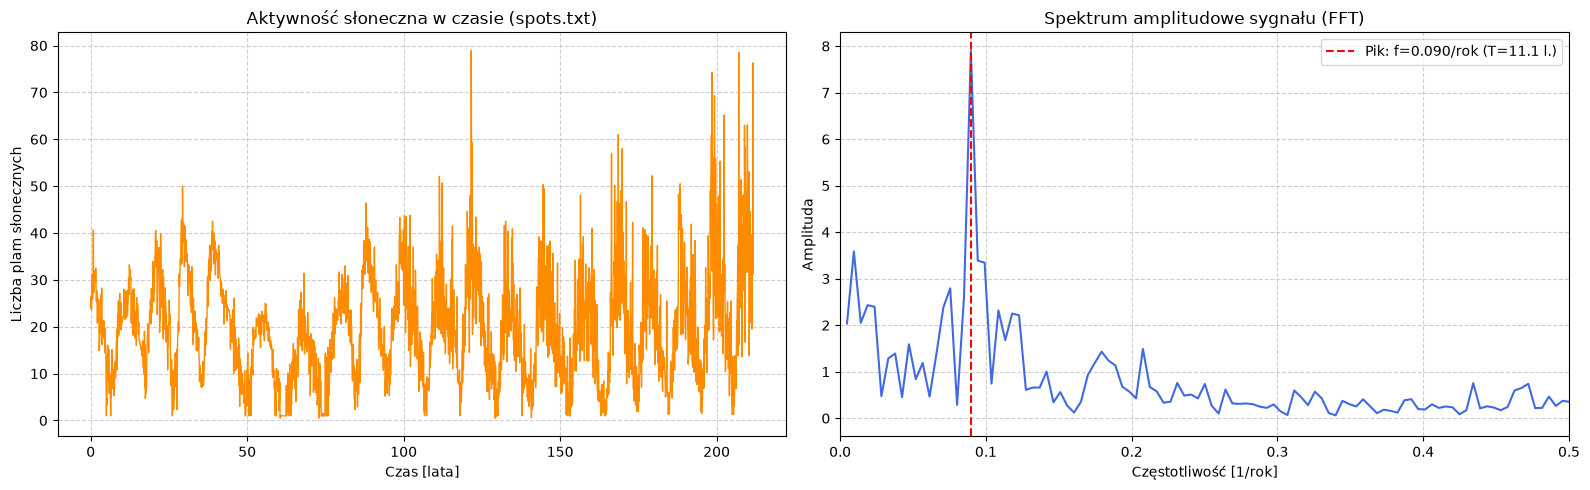

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

spots = np.loadtxt('spots.txt')
N = len(spots)

# Definicja parametrów próbkowania
fs_months = 1.0          # próbek na miesiąc
fs_years = 12.0          # próbek na rok

# Oś czasu w latach (dla lepszej czytelności)
t_years = np.arange(N) / fs_years

# Usunięcie średniej (składowej stałej)
spots_detrended = spots - np.mean(spots)

# Obliczenie FFT
fft_vals = np.fft.fft(spots_detrended)
amplitudes = np.abs(fft_vals) * 2 / N

# Oś częstotliwości (w 1/rok)
freqs_years = np.fft.fftfreq(N, d=1/fs_years)

# Wycięcie połowy widma (od 0 do częstotliwości Nyquista)
half = N // 2
freqs_half = freqs_years[1:half]
amplitudes_half = amplitudes[1:half]

# Znalezienie dominującej częstotliwości
peak_idx = np.argmax(amplitudes_half)
dominant_freq = freqs_half[peak_idx]       # Częstotliwość w [1/rok]
dominant_period_years = 1 / dominant_freq  # Okres w latach
dominant_period_months = dominant_period_years * 12

print(f"Liczba analizowanych miesięcy: {N}")
print(f"Dominująca częstotliwość: {dominant_freq:.4f} [1/rok]")
print(f"Długość cyklu: {dominant_period_years:.2f} lat (~{dominant_period_months:.1f} miesięcy)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Wykres sygnału w czasie
ax1.plot(t_years, spots, color='darkorange', lw=1)
ax1.set_title("Aktywność słoneczna w czasie (spots.txt)")
ax1.set_xlabel("Czas [lata]")
ax1.set_ylabel("Liczba plam słonecznych")
ax1.grid(True, linestyle='--', alpha=0.6)

# Wykres widma amplitudowego
ax2.plot(freqs_half, amplitudes_half, color='royalblue', lw=1.5)
ax2.axvline(dominant_freq, color='red', linestyle='--', label=f'Pik: f={dominant_freq:.3f}/rok (T={dominant_period_years:.1f} l.)')
ax2.set_title("Spektrum amplitudowe sygnału (FFT)")
ax2.set_xlabel("Częstotliwość [1/rok]")
ax2.set_ylabel("Amplituda")
ax2.set_xlim([0, 0.5])  # Zawężenie widoku do interesującego pasma
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Zadanie 3

Wykreśl sygnał $sin(2*pi*t) + sin(4*pi*t)$, T=1s, w=20Hz. Za pomocą FFT, przekształć sygnał do dziedziny częstotliwości. Następnie usuń składowe o częstotliwości 2Hz. Tak zmodyfikowany sygnał przekształć do dziedziny czasu i wykreśl go.

# Zadanie 4

Wczytaj plik err.wav. Wykreśl jego spektrum. Spróbuj także skali logarytmicznej. Określ dominujące w sygnale częstotliwości.

Częstotliwość próbkowania: 44100 Hz
Liczba próbek: 42880 (czas trwania: 0.972 s)

Dominujące częstotliwości w sygnale:
  1. f = 931.8 Hz (amplituda: 0.0091, poziom: -0.0 dBFS)
  2. f = 1242.4 Hz (amplituda: 0.0051, poziom: -5.0 dBFS)


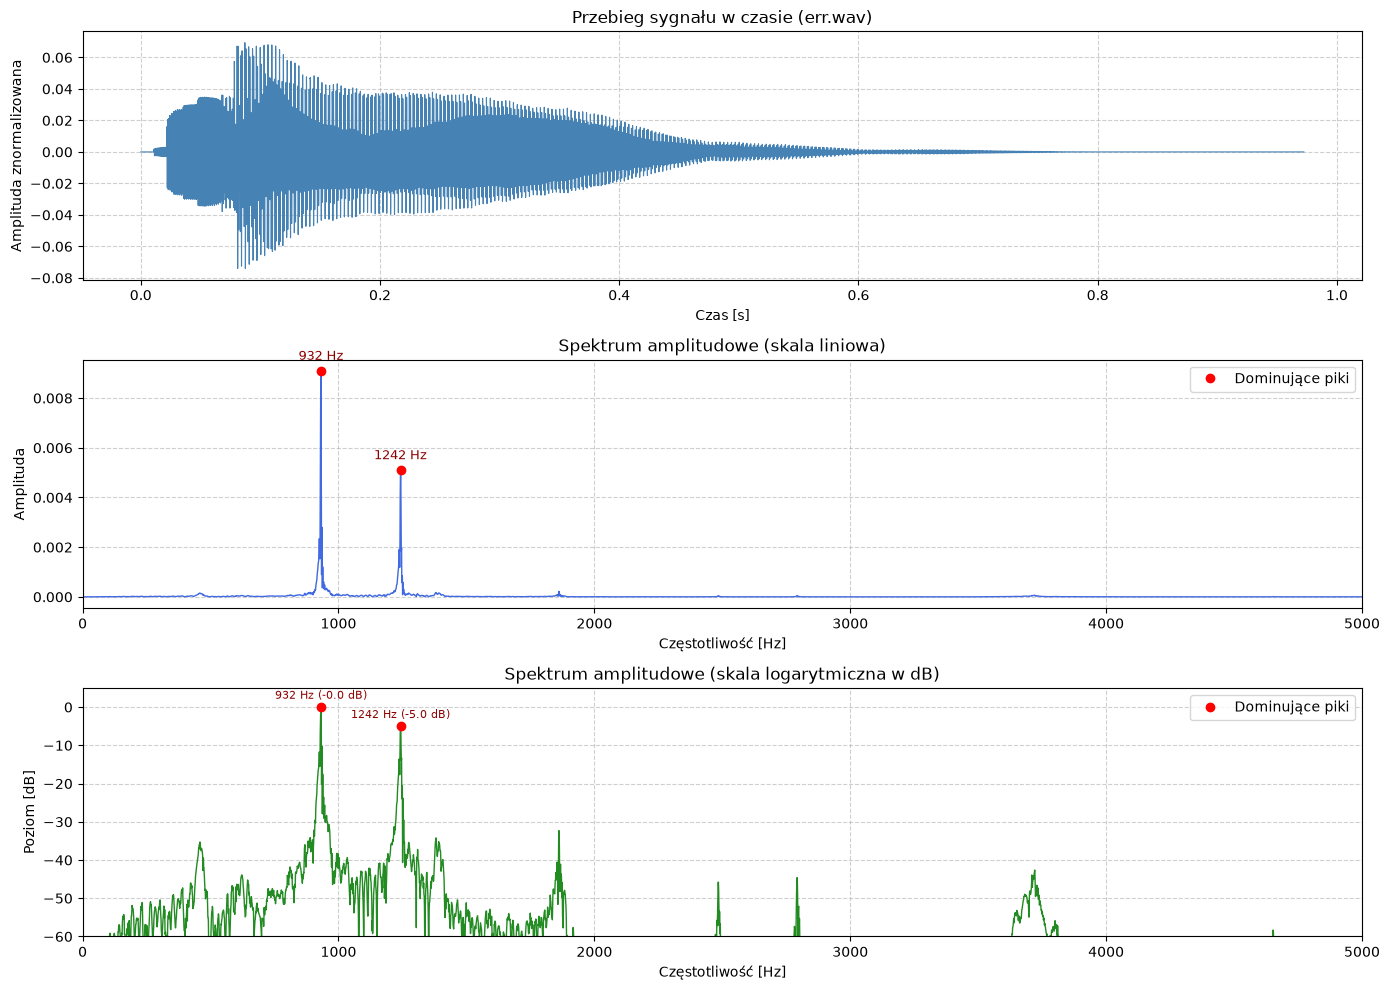

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import find_peaks

# Wczytanie pliku dźwiękowego
fs, data = wavfile.read('err.wav')

if data.ndim > 1:
    data = data[:, 0]

if np.issubdtype(data.dtype, np.integer):
    max_val = np.iinfo(data.dtype).max
    data = data / max_val

N = len(data)
time = np.arange(N) / fs

# Obliczenie FFT i modułu widma
fft_vals = np.fft.fft(data)
amplitudes = np.abs(fft_vals) * 2 / N
freqs = np.fft.fftfreq(N, d=1/fs)

# Wycięcie połowy widma 
half = N // 2
freqs_half = freqs[1:half] 
amp_half = amplitudes[1:half]

# Skala logarytmiczna w decybelach 
eps = 1e-12
amp_db = 20 * np.log10(amp_half / (np.max(amp_half) + eps) + eps)

# Wykrycie dominujących częstotliwości
min_dist = max(1, int(20 / (fs / N)))
peaks, _ = find_peaks(amp_half, height=0.1 * np.max(amp_half), distance=min_dist)

# Posortowanie znalezionych pików malejąco po amplitudzie
sorted_peak_indices = peaks[np.argsort(amp_half[peaks])[::-1]]

print(f"Częstotliwość próbkowania: {fs} Hz")
print(f"Liczba próbek: {N} (czas trwania: {N/fs:.3f} s)")
print("\nDominujące częstotliwości w sygnale:")
for i, idx in enumerate(sorted_peak_indices[:5], start=1):
    f_peak = freqs_half[idx]
    a_peak = amp_half[idx]
    a_db_peak = amp_db[idx]
    print(f"  {i}. f = {f_peak:.1f} Hz (amplituda: {a_peak:.4f}, poziom: {a_db_peak:.1f} dBFS)")

#Wykresy
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10))

# Sygnał w czasie
ax1.plot(time, data, color='steelblue', lw=0.8)
ax1.set_title("Przebieg sygnału w czasie (err.wav)")
ax1.set_xlabel("Czas [s]")
ax1.set_ylabel("Amplituda znormalizowana")
ax1.grid(True, linestyle='--', alpha=0.6)

# Spektrum w skali liniowej
ax2.plot(freqs_half, amp_half, color='royalblue', lw=1)
ax2.plot(freqs_half[sorted_peak_indices[:5]], amp_half[sorted_peak_indices[:5]], 
         'ro', markersize=6, label='Dominujące piki')
for idx in sorted_peak_indices[:5]:
    ax2.annotate(f"{freqs_half[idx]:.0f} Hz",
                 (freqs_half[idx], amp_half[idx]),
                 textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9, color='darkred')
ax2.set_title("Spektrum amplitudowe (skala liniowa)")
ax2.set_xlabel("Częstotliwość [Hz]")
ax2.set_ylabel("Amplituda")
ax2.set_xlim(0, min(fs / 2, 5000))  # zakres do 5 kHz obejmuje większość pasma akustycznego
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

#  Spektrum w skali logarytmicznej (dB)
ax3.plot(freqs_half, amp_db, color='forestgreen', lw=1)
ax3.plot(freqs_half[sorted_peak_indices[:5]], amp_db[sorted_peak_indices[:5]], 
         'ro', markersize=6, label='Dominujące piki')
for idx in sorted_peak_indices[:5]:
    ax3.annotate(f"{freqs_half[idx]:.0f} Hz ({amp_db[idx]:.1f} dB)",
                 (freqs_half[idx], amp_db[idx]),
                 textcoords="offset points", xytext=(0, 6), ha='center', fontsize=8, color='darkred')
ax3.set_title("Spektrum amplitudowe (skala logarytmiczna w dB)")
ax3.set_xlabel("Częstotliwość [Hz]")
ax3.set_ylabel("Poziom [dB]")
ax3.set_xlim(0, min(fs / 2, 5000))
ax3.set_ylim(-60, 5)  # dynamika do 60 dB poniżej wartości szczytowej
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.legend()

plt.tight_layout()
plt.show()